# 02 · Datos — descarga de FaceForensics++ (c23) y recorte de caras
Genera `crops/<categoria>/<video_id>/<frame>.png` (299×299) solo para los videos que usan los experimentos:

| Split | Pares oficiales usados | Categorías |
|---|---|---|
| train | 100 de 360 | original + Deepfakes |
| val | 30 de 70 | original + Deepfakes |
| test | 70 de 70 | original + Deepfakes, Face2Face, FaceSwap, NeuralTextures |

Al terminar: **Save Version → Save & Run All**, y luego crear un *Kaggle Dataset* privado a partir del output (`crops/`) para no repetir este paso. Es la decisión D-05 del cuaderno de decisiones.

In [1]:
# Settings de Kaggle: Accelerator = GPU T4 x2 · Internet = On
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/Gredith/DeepLearning-G8-TA_Repository.git"
ROOT = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path.cwd().parents[1]
if Path("/kaggle").exists() and not ROOT.exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src" / "kaggle_e2"))
print("ROOT =", ROOT)

ROOT = /kaggle/working/repo


In [2]:
!pip install -q --no-deps facenet-pytorch   # --no-deps: evita que reinstale otra versión de torch
import json, pandas as pd, torch
import data as D, preprocess as P
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FFPP = Path("/kaggle/working/ffpp")      # donde descarga el script oficial
CROPS = Path("/kaggle/working/crops")
N_TRAIN, N_VAL, N_TEST, N_FRAMES, SEED = 100, 30, None, 16, 42

## 1. Descarga (script oficial de FF++)
El script de descarga es el que enviaron los autores con la aprobación del acceso (p. ej. `faceforensics_download_v4.py`). **No se versiona ni se enlaza en el repo** porque los términos de FF++ no permiten redistribuirlo: súbanlo a Kaggle como **Dataset privado** (*Add Input → Upload*). La celda siguiente lo encuentra sola en `/kaggle/input/`.

El script descarga todos los videos de cada tipo. Revisen el espacio con `du -sh` después de cada tipo: Kaggle da ~20 GB en `/kaggle/working`. Si no alcanza, borren los videos de cada método después de recortarlo (celda 3).

In [3]:
def _es_script_ffpp(p):
    n = p.name.lower()
    return n.endswith(".py") and "faceforensics" in n and "download" in n
SCRIPT = next((p for p in Path("/kaggle/input").rglob("*.py") if _es_script_ffpp(p)), None) if Path("/kaggle/input").exists() else None
SCRIPT = SCRIPT or next((p for p in Path("/kaggle/working").glob("*.py") if _es_script_ffpp(p)), None)
assert SCRIPT, "No se encontró el script de FF++: súbanlo como Kaggle Dataset privado (Add Input → Upload)"
print("Script:", SCRIPT)
for kind in ["original", "Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]:
    # `echo |` responde a la confirmación de los términos de uso que pide el script
    !echo "" | python {SCRIPT} {FFPP} -d {kind} -c c23 -t videos --server EU2
!du -sh {FFPP}/* 2>/dev/null

Script: /kaggle/input/notebooks/ronaldosegura/robustez-de-detectores-de-deepfakes-ta-dl/faceforensics_download_v4.py
By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Output path: /kaggle/working/ffpp/original_sequences/youtube/c23/videos
100%|███████████████████████████████████████| 1000/1000 [20:54<00:00,  1.25s/it]
By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Output path: /kaggle/working/ffpp/manipulated_sequences/Deepfakes/c23/videos
100%|███████████████████████████████████████| 1000/1000 [20:54<00:00,  1.25s/it]
By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use

## 2. Qué videos se necesitan (splits oficiales, partición por video)

In [4]:
tr = D.subset_pairs(D.load_pairs("results/splits", "train"), N_TRAIN, SEED)
va = D.subset_pairs(D.load_pairs("results/splits", "val"), N_VAL, SEED)
te = D.subset_pairs(D.load_pairs("results/splits", "test"), N_TEST, SEED)
need = {}
for pairs, cats in [(tr, ["Deepfakes"]), (va, ["Deepfakes"]), (te, D.METHODS)]:
    reals, fakes = D.video_ids(pairs)
    need.setdefault(D.REAL, set()).update(reals)
    for c in cats: need.setdefault(c, set()).update(fakes)
need = {k: sorted(v) for k, v in need.items()}
# chequeo anti-fuga: ninguna identidad en dos splits
ids = {s: {v for p in ps for v in p} for s, ps in [("train", tr), ("val", va), ("test", te)]}
assert not (ids["train"] & ids["val"]) and not (ids["train"] & ids["test"]) and not (ids["val"] & ids["test"])
{k: len(v) for k, v in need.items()}

{'original': 400,
 'Deepfakes': 400,
 'Face2Face': 140,
 'FaceSwap': 140,
 'NeuralTextures': 140}

## 3. Recorte de caras (MTCNN, caja ×1.3, 16 frames equiespaciados por video)
> **Licencia:** los recortes y la inspección visual (tag `caras`) no se suben a GitHub. Antes de versionar este notebook ejecutado, correr `python tools/limpiar_caras.py`.

In [5]:
rows = P.process_all(FFPP, CROPS, need, n_frames=N_FRAMES, device=DEVICE)
man = pd.DataFrame(rows); man.to_csv(CROPS / "manifest.csv", index=False)
print(man.groupby("categoria").agg(videos=("video", "count"), sin_video=("existe_video", lambda s: (~s).sum()),
                                   recortes=("recortes", "sum"), videos_sin_cara=("recortes", lambda s: (s == 0).sum())))

original:   0%|          | 0/400 [00:00<?, ?it/s]

Deepfakes:   0%|          | 0/400 [00:00<?, ?it/s]

Face2Face:   0%|          | 0/140 [00:00<?, ?it/s]

FaceSwap:   0%|          | 0/140 [00:00<?, ?it/s]

NeuralTextures:   0%|          | 0/140 [00:00<?, ?it/s]

                videos  sin_video  recortes  videos_sin_cara
categoria                                                   
Deepfakes          400          0      6394                0
Face2Face          140          0      2240                0
FaceSwap           140          0      2240                0
NeuralTextures     140          0      2240                0
original           400          0      6400                0


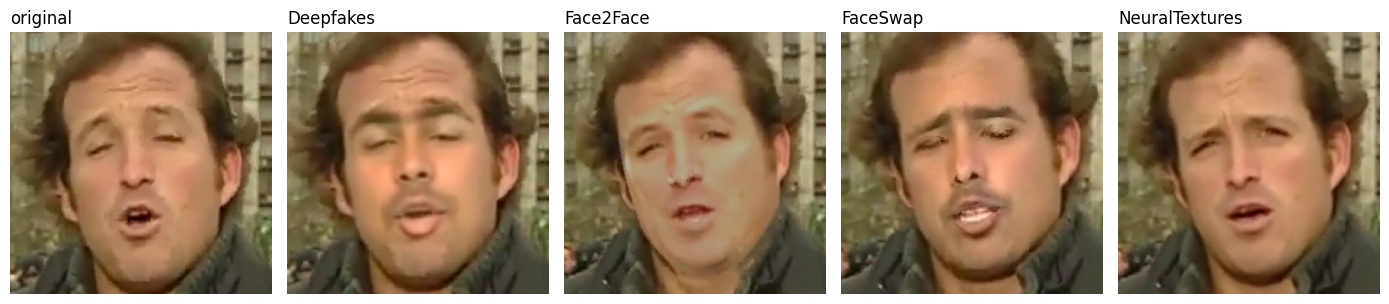

In [6]:
# Inspección visual: real vs. cada manipulación del mismo target
import matplotlib.pyplot as plt
from PIL import Image
a, b = te[0]
paths = [CROPS / D.REAL / a] + [CROPS / m / f"{a}_{b}" for m in D.METHODS]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, p in zip(axes, paths):
    fs = sorted(p.glob("*.png"))
    if fs: ax.imshow(Image.open(fs[len(fs) // 2]))
    ax.set_title(p.parent.name, loc="left"); ax.axis("off")
plt.tight_layout(); plt.savefig(ROOT / "results" / "ejemplo_recortes.png", dpi=150); plt.show()

In [7]:
# Liberar espacio: los videos ya no se necesitan
# !rm -rf {FFPP}
#!du -sh {CROPS}